# Лабораторная работа № 2. Исследование логистической и линейной регрессий

**Цель работы** — исследовать логистическую регрессию для классификации манёвров робота и линейную регрессию для оценки доли времени работы CPU в пользовательском режиме. На этом этапе подготовим данные и измерим качество исходных моделей.

## 1. Подготовка данных

Загрузим те же локальные CSV и повторим разделение из первой лабораторной. У робота используем 24 показания датчиков и цель `class`, у CPU — 21 числовой признак и цель `usr`. Сохраняем порядок строк и зазор 90 строк перед тестовым блоком робота. Тестовые выборки используем для итоговой оценки.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

robot = pd.read_csv("data/wall_following_robot_24.csv")
cpu = pd.read_csv("data/cpu_act_44132.csv")

X_robot = robot.drop(columns="class")
y_robot = robot["class"]
X_cpu = cpu.drop(columns="usr")
y_cpu = cpu["usr"]

# Правая граница среза не включается.
robot_train = slice(0, 4274)
robot_test = slice(4364, 5456)
cpu_train = slice(0, 6553)
cpu_test = slice(6553, 8192)

assert len(robot) == robot_test.stop and len(cpu) == cpu_test.stop

X_robot_train, X_robot_test = X_robot.iloc[robot_train], X_robot.iloc[robot_test]
y_robot_train, y_robot_test = y_robot.iloc[robot_train], y_robot.iloc[robot_test]
X_cpu_train, X_cpu_test = X_cpu.iloc[cpu_train], X_cpu.iloc[cpu_test]
y_cpu_train, y_cpu_test = y_cpu.iloc[cpu_train], y_cpu.iloc[cpu_test]

assert y_robot_train.nunique() == 4
print(f"Робот: {len(X_robot_train)} обучающих и {len(X_robot_test)} тестовых строк.")
print(f"CPU: {len(X_cpu_train)} обучающих и {len(X_cpu_test)} тестовых строк.")

Робот: 4274 обучающих и 1092 тестовых строк.
CPU: 6553 обучающих и 1639 тестовых строк.


## 2. Создание бейзлайна и оценка качества

### Классификация манёвров робота

Обучим `LogisticRegression` на исходных признаках. Стандартный решатель `lbfgs` обучает одну многоклассовую модель для всех четырёх манёвров. При предварительной проверке на обучающей выборке стандартный лимит в 100 итераций был достигнут и sklearn выдал `ConvergenceWarning`. Увеличим только лимит `max_iter` до 1000, чтобы оптимизатор мог завершить работу. На тесте рассчитаем Accuracy и F1-macro и построим матрицу ошибок.

Итераций lbfgs: 268 из 1000.


,Accuracy,F1-macro
Модель,,
LogisticRegression,0.7134,0.6928


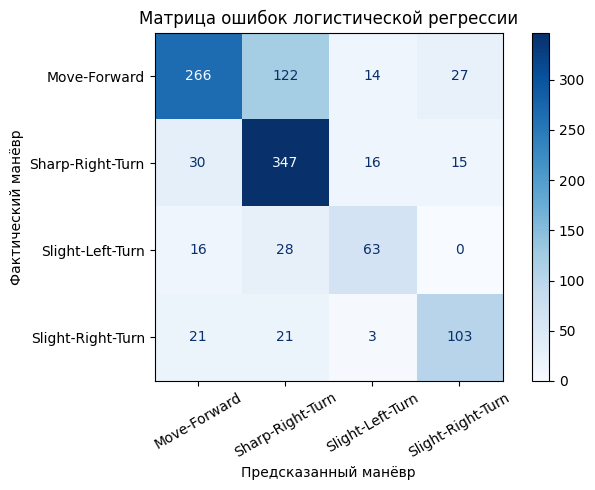

In [2]:
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

robot_baseline = LogisticRegression(max_iter=1000)
robot_baseline.fit(X_robot_train, y_robot_train)
print(f"Итераций lbfgs: {robot_baseline.n_iter_.max()} из {robot_baseline.max_iter}.")
y_robot_pred = robot_baseline.predict(X_robot_test)

baseline_classification = pd.DataFrame(
    {
        "Accuracy": [accuracy_score(y_robot_test, y_robot_pred)],
        "F1-macro": [f1_score(y_robot_test, y_robot_pred, average="macro")],
    },
    index=pd.Index(["LogisticRegression"], name="Модель"),
)
display(baseline_classification.round(4))

fig, ax = plt.subplots(figsize=(7, 5))
ConfusionMatrixDisplay.from_predictions(
    y_robot_test, y_robot_pred, labels=robot_baseline.classes_,
    cmap="Blues", values_format="d", xticks_rotation=30, ax=ax,
)
ax.set(
    title="Матрица ошибок логистической регрессии",
    xlabel="Предсказанный манёвр",
    ylabel="Фактический манёвр",
)
fig.tight_layout()
plt.show()

### Регрессия CPU Activity

Обучим `LinearRegression` на исходных признаках. На тесте рассчитаем MAE, RMSE и R². На графике диагональ соответствует точному прогнозу. Покажем все значения, включая возможные предсказания за пределами 0–100%.

,"MAE, п. п.","RMSE, п. п.",R²
Модель,,,
LinearRegression,6.2053,8.9867,0.7246


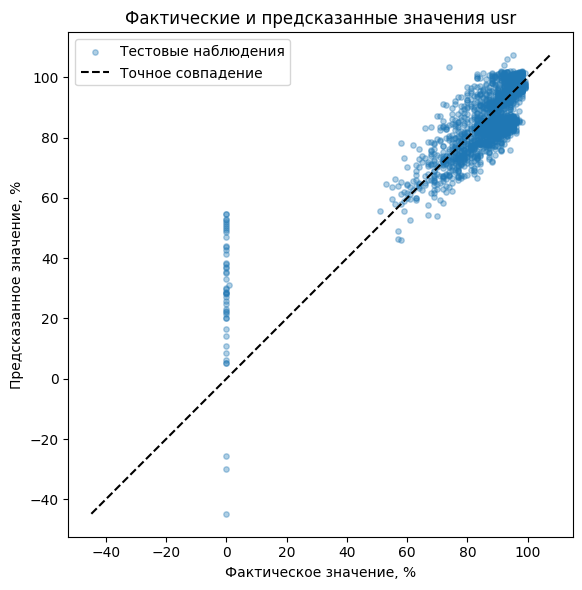

In [3]:
cpu_baseline = LinearRegression()
cpu_baseline.fit(X_cpu_train, y_cpu_train)
y_cpu_pred = cpu_baseline.predict(X_cpu_test)

baseline_regression = pd.DataFrame(
    {
        "MAE, п. п.": [mean_absolute_error(y_cpu_test, y_cpu_pred)],
        "RMSE, п. п.": [mean_squared_error(y_cpu_test, y_cpu_pred) ** 0.5],
        "R²": [r2_score(y_cpu_test, y_cpu_pred)],
    },
    index=pd.Index(["LinearRegression"], name="Модель"),
)
display(baseline_regression.round(4))

low = min(0, y_cpu_pred.min())
high = max(100, y_cpu_pred.max())
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_cpu_test, y_cpu_pred, s=15, alpha=0.35, label="Тестовые наблюдения")
ax.plot([low, high], [low, high], "--", color="black", label="Точное совпадение")
ax.set(
    title="Фактические и предсказанные значения usr",
    xlabel="Фактическое значение, %",
    ylabel="Предсказанное значение, %",
    aspect="equal",
)
ax.legend()
fig.tight_layout()
plt.show()

### Выводы

- **Классификация.** Accuracy составила 71,34%, F1-macro — 0,6928. Небольшой левый поворот модель распознала в 63 из 107 случаев. Оптимизатор сошёлся за 268 итераций.
- **Регрессия.** Среднее абсолютное отклонение составило 6,21 п. п., RMSE — 8,99 п. п., R² — 0,7246. За диапазон 0–100% вышли 103 тестовых прогнозов. При расчёте метрик использованы исходные прогнозы.

## 3. Улучшение бейзлайна

### Логистическая регрессия

Проверим три гипотезы. Масштабирование может улучшить работу оптимизатора и сделать регуляризацию сопоставимой для признаков разных масштабов. Подбор `C` может улучшить баланс между качеством подгонки и регуляризацией. Меньшее `C` означает более сильную регуляризацию. Веса `balanced` могут улучшить распознавание редких манёвров, поскольку дают им больший вес при обучении.

Используем три последовательных фолда внутри обучающей выборки, с зазором 90 строк. Проверим наличие четырёх классов в обеих частях каждого фолда. Выберем модель по среднему F1-macro. Все преобразования выполняются внутри `Pipeline`. Для всей сетки зададим запас в 5000 итераций, так как исходная модель уже превышала стандартный лимит, а некоторые значения `C` задают более слабую регуляризацию. Предупреждения о сходимости остаются видимыми.

In [4]:
import numpy as np
from sklearn.linear_model import Ridge
from sklearn.metrics import make_scorer
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

robot_cv = TimeSeriesSplit(n_splits=3, gap=90)
cpu_cv = TimeSeriesSplit(n_splits=3)

for train_idx, val_idx in robot_cv.split(X_robot_train):
    assert val_idx[0] - train_idx[-1] - 1 == 90
    assert y_robot_train.iloc[train_idx].nunique() == 4
    assert y_robot_train.iloc[val_idx].nunique() == 4

robot_search = GridSearchCV(
    Pipeline([
        ("scale", "passthrough"),
        ("model", LogisticRegression(max_iter=5000)),
    ]),
    {
        "scale": ["passthrough", StandardScaler()],
        "model__C": [0.01, 0.1, 1, 10, 100],
        "model__class_weight": [None, "balanced"],
    },
    cv=robot_cv, scoring="f1_macro", refit=True, error_score="raise",
)
robot_search.fit(X_robot_train, y_robot_train)

logistic_results = pd.DataFrame(robot_search.cv_results_)
logistic_cv_table = pd.DataFrame({
    "Масштабирование": logistic_results["param_scale"].map(
        lambda scale: "StandardScaler" if isinstance(scale, StandardScaler) else "Нет"
    ),
    "C": logistic_results["param_model__C"],
    "Веса классов": logistic_results["param_model__class_weight"].fillna("None"),
    "F1-macro (CV)": logistic_results["mean_test_score"],
})
display(logistic_cv_table.sort_values("F1-macro (CV)", ascending=False).round(4))

robot_improved = robot_search.best_estimator_
best_logistic_params = {
    "standardize": isinstance(robot_improved.named_steps["scale"], StandardScaler),
    "C": robot_search.best_params_["model__C"],
    "class_weight": robot_search.best_params_["model__class_weight"],
    "max_iter": robot_improved.named_steps["model"].max_iter,
}
iterations = robot_improved.named_steps["model"].n_iter_.max()
print("Выбранные настройки:", best_logistic_params)
print(f"Итераций при обучении выбранной модели: {iterations} из {best_logistic_params['max_iter']}.")

,Масштабирование,C,Веса классов,F1-macro (CV)
18,Нет,100.00,balanced,0.5872
15,StandardScaler,10.00,balanced,0.5871
14,Нет,10.00,balanced,0.5870
19,StandardScaler,100.00,balanced,0.5867
10,Нет,1.00,balanced,0.5807
11,StandardScaler,1.00,balanced,0.5787
12,Нет,10.00,None,0.5735
13,StandardScaler,10.00,None,0.5731
17,StandardScaler,100.00,None,0.5718
16,Нет,100.00,None,0.5712


Выбранные настройки: {'standardize': False, 'C': 100, 'class_weight': 'balanced', 'max_iter': 5000}
Итераций при обучении выбранной модели: 269 из 5000.


### Линейная регрессия

Квадраты признаков и парные произведения могут описать нелинейные зависимости. L2-регуляризация в Ridge может уменьшить влияние нестабильных коэффициентов. Для Ridge стандартизуем признаки внутри каждого фолда, чтобы штраф применялся к коэффициентам на сопоставимых масштабах.

На трёх последовательных фолдах сравним исходную модель, полиномиальную регрессию степени 2 и пять вариантов Ridge. Для каждого варианта посчитаем MAE с исходными прогнозами и с ограничением 0–100%. Ограничение применяется только к выходу модели. Выберем строку с наименьшим средним MAE. При точном равенстве используем первый вариант в таблице, отдавая предпочтение исходным прогнозам внутри одной модели.

In [5]:
def clipped_mae(y_true, y_pred):
    return mean_absolute_error(y_true, np.clip(y_pred, 0, 100))


cpu_configs = [
    ("LinearRegression", "Нет", None, None, Pipeline([("model", LinearRegression())])),
    ("Полиномиальная регрессия", "Полином", 2, None, Pipeline([
        ("poly", PolynomialFeatures(degree=2, include_bias=False)),
        ("model", LinearRegression()),
    ])),
]
for alpha in [0.01, 0.1, 1, 10, 100]:
    cpu_configs.append(("Ridge", "StandardScaler", None, alpha, Pipeline([
        ("scale", StandardScaler()),
        ("model", Ridge(alpha=alpha)),
    ])))

cpu_cv_rows = []
for index, (name, transform, degree, alpha, pipeline) in enumerate(cpu_configs):
    scores = cross_validate(
        pipeline, X_cpu_train, y_cpu_train, cv=cpu_cv, error_score="raise",
        scoring={
            "raw": "neg_mean_absolute_error",
            "clipped": make_scorer(clipped_mae, greater_is_better=False),
        },
    )
    for clip in [False, True]:
        key = "test_clipped" if clip else "test_raw"
        cpu_cv_rows.append({
            "Вариант": index, "Модель": name, "Преобразование": transform,
            "Степень": degree, "alpha": alpha, "Ограничение 0–100%": clip,
            "MAE (CV), п. п.": -scores[key].mean(),
        })

linear_cv_table = pd.DataFrame(cpu_cv_rows)
display(linear_cv_table.drop(columns="Вариант").round(4))

winner = cpu_cv_rows[linear_cv_table["MAE (CV), п. п."].idxmin()]
_, _, degree, alpha, cpu_improved = cpu_configs[winner["Вариант"]]
best_linear_params = {
    "model": type(cpu_improved.named_steps["model"]).__name__,
    "standardize": "scale" in cpu_improved.named_steps,
    "polynomial_degree": degree,
    "include_bias": False if degree is not None else None,
    "alpha": alpha,
    "clip_range": (0, 100) if winner["Ограничение 0–100%"] else None,
}
cpu_improved.fit(X_cpu_train, y_cpu_train)
print("Выбранные настройки:", best_linear_params)

,Модель,Преобразование,Степень,alpha,Ограничение 0–100%,"MAE (CV), п. п."
0,LinearRegression,Нет,NaN,NaN,False,6.2471
1,LinearRegression,Нет,NaN,NaN,True,5.9012
2,Полиномиальная регрессия,Полином,2.0,NaN,False,2.5318
3,Полиномиальная регрессия,Полином,2.0,NaN,True,2.4145
4,Ridge,StandardScaler,NaN,0.01,False,6.2470
5,Ridge,StandardScaler,NaN,0.01,True,5.9011
6,Ridge,StandardScaler,NaN,0.10,False,6.2468
7,Ridge,StandardScaler,NaN,0.10,True,5.9009
8,Ridge,StandardScaler,NaN,1.00,False,6.2442
9,Ridge,StandardScaler,NaN,1.00,True,5.8990


Выбранные настройки: {'model': 'LinearRegression', 'standardize': False, 'polynomial_degree': 2, 'include_bias': False, 'alpha': None, 'clip_range': (0, 100)}


### Сравнение на тесте

Оценим выбранные модели на прежних тестовых выборках. Используем сохранённые результаты исходных моделей и построим отдельный график для каждой метрики.

,Accuracy,F1-macro
Исходный,0.7134,0.6928
Улучшенный,0.6694,0.6652


,"MAE, п. п.","RMSE, п. п.",R²
Исходный,6.2053,8.9867,0.7246
Улучшенный,2.3034,3.7218,0.9528


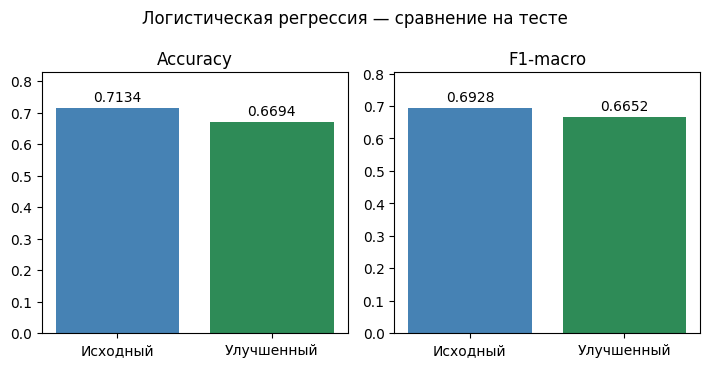

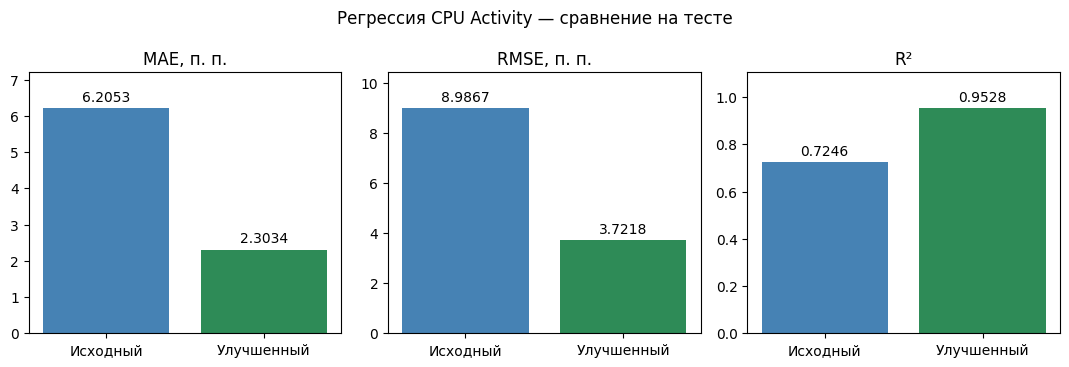

In [6]:
y_robot_improved = robot_improved.predict(X_robot_test)
y_cpu_improved = cpu_improved.predict(X_cpu_test)
if best_linear_params["clip_range"] is not None:
    y_cpu_improved = np.clip(y_cpu_improved, *best_linear_params["clip_range"])

classification_comparison = pd.DataFrame([
    baseline_classification.iloc[0].to_dict(),
    {
        "Accuracy": accuracy_score(y_robot_test, y_robot_improved),
        "F1-macro": f1_score(y_robot_test, y_robot_improved, average="macro"),
    },
], index=["Исходный", "Улучшенный"])

regression_comparison = pd.DataFrame([
    baseline_regression.iloc[0].to_dict(),
    {
        "MAE, п. п.": mean_absolute_error(y_cpu_test, y_cpu_improved),
        "RMSE, п. п.": mean_squared_error(y_cpu_test, y_cpu_improved) ** 0.5,
        "R²": r2_score(y_cpu_test, y_cpu_improved),
    },
], index=["Исходный", "Улучшенный"])

display(classification_comparison.round(4), regression_comparison.round(4))

for title, table in [
    ("Логистическая регрессия", classification_comparison),
    ("Регрессия CPU Activity", regression_comparison),
]:
    fig, axes = plt.subplots(1, len(table.columns), figsize=(3.6 * len(table.columns), 3.7))
    for ax, metric in zip(axes, table.columns):
        bars = ax.bar(table.index, table[metric], color=["steelblue", "seagreen"])
        ax.bar_label(bars, fmt="%.4f", padding=3)
        ax.set_title(metric)
        ax.margins(y=0.16)
    fig.suptitle(title + " — сравнение на тесте")
    fig.tight_layout()
    plt.show()

### Выводы

- **Логистическая регрессия.** В среднем по сетке F1-macro со StandardScaler составила 0,5580, без него — 0,5609. Наибольшее среднее по значениям `C` было у `C=10.0`. Средние для `None` и `balanced` составили 0,5471 и 0,5718. Лучшая комбинация — без масштабирования, `C=100`, `class_weight=balanced`. F1-macro на кросс-валидации выросла с 0,5709 до 0,5872. На тесте F1-macro снизилась (0,6928 → 0,6652), Accuracy составила 0,7134 → 0,6694. Перебор прошёл без предупреждений о сходимости. Финальная модель сошлась за 269 итераций.
- **Регрессия CPU.** Исходная модель дала MAE 6,2471 п. п. на кросс-валидации, а после ограничения — 5,9012 п. п. Для полиномиальной модели эти оценки составили 2,5318 и 2,4145 п. п. Лучший результат Ridge — 5,7954 п. п. Минимальную ошибку по всем вариантам дала модель Полиномиальная регрессия с ограничением 0–100% (2,4145 п. п.). На тесте MAE на тесте снизилась (6,2053 → 2,3034 п. п.), RMSE составила 8,9867 → 3,7218 п. п., R² — 0,7246 → 0,9528.

Выбранные параметры и преобразования сохранены в `best_logistic_params` и `best_linear_params`.

## 4. Самостоятельная реализация алгоритмов

**Линейная регрессия.** Прогноз имеет вид $\hat y=x^\top w+b$. Метод наименьших квадратов минимизирует $\sum_i(y_i-\hat y_i)^2$. Сначала центрируем обучающие признаки и ответы и находим $w$ через `np.linalg.lstsq`. Затем восстанавливаем свободный коэффициент $b=\bar y-\bar x^\top w$.

**Многоклассовая логистическая регрессия.** Для каждого класса вычисляем оценку $z_{ik}=x_i^\top w_k+b_k$. Softmax даёт вероятности $p_{ik}=\exp(z_{ik})/\sum_j\exp(z_{ij})$. Для устойчивости вычитаем из оценок каждой строки её максимум и считаем логарифмы вероятностей напрямую. Выбираем класс с наибольшей вероятностью.

Пусть $a_i$ — вес объекта, а $S=\sum_i a_i$. Минимизируем взвешенную кросс-энтропию с L2-штрафом в той же нормировке, что и sklearn:

$$L=-\frac{1}{S}\sum_i a_i\log p_{i,y_i}+\frac{\lVert W\rVert_F^2}{2CS}.$$

При `balanced` вес объекта класса $k$ равен $n/(K n_k)$, где $K$ — число классов, а $n_k$ — число объектов этого класса в обучающей выборке. Градиент по оценкам равен $a_i(p_{ik}-\mathbf{1}[y_i=k])/S$. Градиент по $W$ получаем умножением на признаки и добавлением $W/(CS)$. Свободные коэффициенты не штрафуем. Передадим собственную функцию потерь и градиент оптимизатору L-BFGS-B.

In [7]:
from scipy.optimize import check_grad, minimize


class NumpyLinearRegression:
    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        X_mean = X.mean(axis=0)
        y_mean = y.mean()
        self.coef_ = np.linalg.lstsq(X - X_mean, y - y_mean, rcond=None)[0]
        self.intercept_ = y_mean - X_mean @ self.coef_
        return self

    def predict(self, X):
        return np.asarray(X, dtype=float) @ self.coef_ + self.intercept_


class NumpyLogisticRegression:
    def __init__(self, C=1.0, class_weight=None, max_iter=1000):
        self.C = C
        self.class_weight = class_weight
        self.max_iter = max_iter

    @staticmethod
    def _log_softmax(scores):
        shifted = scores - scores.max(axis=1, keepdims=True)
        return shifted - np.log(np.exp(shifted).sum(axis=1, keepdims=True))

    def _loss_gradient(self, params, X, targets, weights, n_classes):
        n_features = X.shape[1]
        parameters = params.reshape(n_classes, n_features + 1)
        coef = parameters[:, :-1]
        intercept = parameters[:, -1]
        log_probs = self._log_softmax(X @ coef.T + intercept)
        rows = np.arange(len(X))
        total_weight = weights.sum()
        l2 = 1 / (self.C * total_weight)
        loss = -np.dot(weights, log_probs[rows, targets]) / total_weight
        loss += 0.5 * l2 * np.sum(coef ** 2)

        residual = np.exp(log_probs)
        residual[rows, targets] -= 1
        residual *= weights[:, None] / total_weight
        grad_coef = residual.T @ X + l2 * coef
        grad_intercept = residual.sum(axis=0)
        gradient = np.column_stack((grad_coef, grad_intercept)).ravel()
        return loss, gradient

    def fit(self, X, y):
        if not np.isfinite(self.C) or self.C <= 0:
            raise ValueError("C должно быть положительным конечным числом.")
        X = np.asarray(X, dtype=float)
        self.classes_, targets, counts = np.unique(y, return_inverse=True, return_counts=True)
        n_classes = len(self.classes_)
        if n_classes < 2:
            raise ValueError("Для классификации нужны хотя бы два класса.")
        if self.class_weight is None:
            weights = np.ones(len(X))
        elif self.class_weight == "balanced":
            weights = len(X) / (n_classes * counts[targets])
        elif isinstance(self.class_weight, dict):
            weights = np.array([self.class_weight.get(label, 1.0) for label in y], dtype=float)
        else:
            raise ValueError("class_weight должно быть None, balanced или словарём.")
        if not np.isfinite(weights).all() or np.any(weights < 0) or weights.sum() <= 0:
            raise ValueError("Веса должны быть конечными, неотрицательными и с положительной суммой.")

        start = np.zeros(n_classes * (X.shape[1] + 1))
        self.result_ = minimize(
            self._loss_gradient, start, args=(X, targets, weights, n_classes),
            jac=True, method="L-BFGS-B",
            options={
                "maxiter": self.max_iter, "maxls": 50,
                "gtol": 1e-4, "ftol": 64 * np.finfo(float).eps,
            },
        )
        parameters = self.result_.x.reshape(n_classes, X.shape[1] + 1)
        self.coef_ = parameters[:, :-1]
        self.intercept_ = parameters[:, -1]
        return self

    def predict_proba(self, X):
        scores = np.asarray(X, dtype=float) @ self.coef_.T + self.intercept_
        return np.exp(self._log_softmax(scores))

    def predict(self, X):
        return self.classes_[np.argmax(self.predict_proba(X), axis=1)]

### Проверка на простых примерах

Линейная модель должна восстановить прямую `y = 2x + 3`. Для логистической регрессии используем три класса, каждый со своим активным признаком. Проверим метки, сумму вероятностей, устойчивость на больших оценках и совпадение аналитического градиента с численным для взвешенной функции потерь.

In [8]:
demo_linear = NumpyLinearRegression().fit([[0], [1], [2]], [3, 5, 7])
np.testing.assert_allclose(demo_linear.coef_, [2])
np.testing.assert_allclose(demo_linear.intercept_, 3)
np.testing.assert_allclose(demo_linear.predict([[-1], [3]]), [1, 9])

demo_X = np.eye(3)
demo_y = ["A", "B", "C"]
demo_logistic = NumpyLogisticRegression(class_weight="balanced").fit(demo_X, demo_y)
assert demo_logistic.result_.success, demo_logistic.result_.message
assert demo_logistic.predict(demo_X).tolist() == demo_y
np.testing.assert_allclose(demo_logistic.predict_proba(demo_X).sum(axis=1), 1)
np.testing.assert_allclose(
    np.exp(demo_logistic._log_softmax(np.array([[1000., 1000., -1000.]]))),
    [[0.5, 0.5, 0]],
)

gradient_args = (demo_X, np.arange(3), np.array([1., 2., 4.]), 3)
gradient_point = np.linspace(-0.2, 0.2, 12)
gradient_error = check_grad(
    lambda p: demo_logistic._loss_gradient(p, *gradient_args)[0],
    lambda p: demo_logistic._loss_gradient(p, *gradient_args)[1],
    gradient_point,
)
assert gradient_error < 1e-6
print(f"Все проверки пройдены. Ошибка численной проверки градиента: {gradient_error:.2e}.")

Все проверки пройдены. Ошибка численной проверки градиента: 3.05e-08.


### Обучение на исходных и выбранных настройках

Воспроизведём исходные настройки и настройки, выбранные в разделе 3. Полиномиальные признаки строим со степенью 2 без столбца единиц, поскольку свободный коэффициент уже есть в собственной модели. Преобразование обучаем на обучающей части. Ограничиваем только прогнозы улучшенного регрессора.

In [9]:
robot_own = NumpyLogisticRegression(max_iter=robot_baseline.max_iter)
robot_own.fit(X_robot_train, y_robot_train)
cpu_own = NumpyLinearRegression().fit(X_cpu_train, y_cpu_train)

robot_own_improved = NumpyLogisticRegression(
    C=best_logistic_params["C"],
    class_weight=best_logistic_params["class_weight"],
    max_iter=best_logistic_params["max_iter"],
)
robot_own_train = X_robot_train
robot_own_test = X_robot_test
if best_logistic_params["standardize"]:
    robot_scaler = StandardScaler()
    robot_own_train = robot_scaler.fit_transform(X_robot_train)
    robot_own_test = robot_scaler.transform(X_robot_test)
robot_own_improved.fit(robot_own_train, y_robot_train)

cpu_poly = PolynomialFeatures(
    degree=best_linear_params["polynomial_degree"],
    include_bias=best_linear_params["include_bias"],
)
X_cpu_train_poly = cpu_poly.fit_transform(X_cpu_train)
X_cpu_test_poly = cpu_poly.transform(X_cpu_test)
cpu_own_improved = NumpyLinearRegression().fit(X_cpu_train_poly, y_cpu_train)

y_robot_own = robot_own.predict(X_robot_test)
y_robot_own_improved = robot_own_improved.predict(robot_own_test)
y_cpu_own = cpu_own.predict(X_cpu_test)
y_cpu_own_improved = cpu_own_improved.predict(X_cpu_test_poly)
if best_linear_params["clip_range"] is not None:
    y_cpu_own_improved = np.clip(y_cpu_own_improved, *best_linear_params["clip_range"])

Проверим статус оптимизатора, суммы вероятностей и конечность прогнозов. Сравним предсказания каждой собственной модели с библиотечной моделью при тех же настройках и посчитаем все метрики.

In [10]:
for name, model, features in [
    ("Исходная логистическая", robot_own, X_robot_test),
    ("Улучшенная логистическая", robot_own_improved, robot_own_test),
]:
    result = model.result_
    print(f"{name}: успех = {result.success}, итераций = {result.nit}. {result.message}")
    assert result.success, result.message
    probabilities = model.predict_proba(features)
    assert np.isfinite(probabilities).all()
    np.testing.assert_allclose(probabilities.sum(axis=1), 1)

assert np.isfinite(y_cpu_own).all() and np.isfinite(y_cpu_own_improved).all()
if best_linear_params["clip_range"] is not None:
    lower, upper = best_linear_params["clip_range"]
    assert ((lower <= y_cpu_own_improved) & (y_cpu_own_improved <= upper)).all()

model_names = [
    "Исходная sklearn", "Улучшенная sklearn",
    "Собственная", "Улучшенная собственная",
]
classification_final = pd.DataFrame(
    classification_comparison.to_dict(orient="records")
    + [
        {"Accuracy": accuracy_score(y_robot_test, prediction),
         "F1-macro": f1_score(y_robot_test, prediction, average="macro")}
        for prediction in [y_robot_own, y_robot_own_improved]
    ],
    index=pd.Index(model_names, name="Модель"),
)
regression_final = pd.DataFrame(
    regression_comparison.to_dict(orient="records")
    + [
        {"MAE, п. п.": mean_absolute_error(y_cpu_test, prediction),
         "RMSE, п. п.": mean_squared_error(y_cpu_test, prediction) ** 0.5,
         "R²": r2_score(y_cpu_test, prediction)}
        for prediction in [y_cpu_own, y_cpu_own_improved]
    ],
    index=pd.Index(model_names, name="Модель"),
)
display(classification_final.round(4), regression_final.round(4))

robot_disagreements = [
    int(np.count_nonzero(y_robot_own != y_robot_pred)),
    int(np.count_nonzero(y_robot_own_improved != y_robot_improved)),
]
cpu_max_differences = [
    float(np.max(np.abs(y_cpu_own - y_cpu_pred))),
    float(np.max(np.abs(y_cpu_own_improved - y_cpu_improved))),
]
print("Логистическая регрессия, число отличающихся меток:", robot_disagreements)
print("Линейная регрессия, максимальные отклонения, п. п.:",
      [f"{value:.3g}" for value in cpu_max_differences])

Исходная логистическая: успех = True, итераций = 274. CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
Улучшенная логистическая: успех = True, итераций = 293. CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL


,Accuracy,F1-macro
Модель,,
Исходная sklearn,0.7134,0.6928
Улучшенная sklearn,0.6694,0.6652
Собственная,0.7134,0.6928
Улучшенная собственная,0.6694,0.6652


,"MAE, п. п.","RMSE, п. п.",R²
Модель,,,
Исходная sklearn,6.2053,8.9867,0.7246
Улучшенная sklearn,2.3034,3.7218,0.9528
Собственная,6.2053,8.9867,0.7246
Улучшенная собственная,2.3034,3.7218,0.9528


Логистическая регрессия, число отличающихся меток: [0, 0]
Линейная регрессия, максимальные отклонения, п. п.: ['0', '0.000305']


Построим графики сравнения четырёх моделей. Для каждой метрики используем отдельную ось.

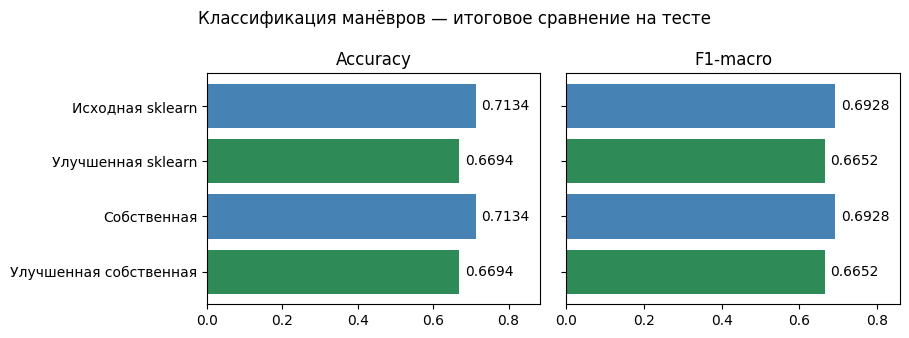

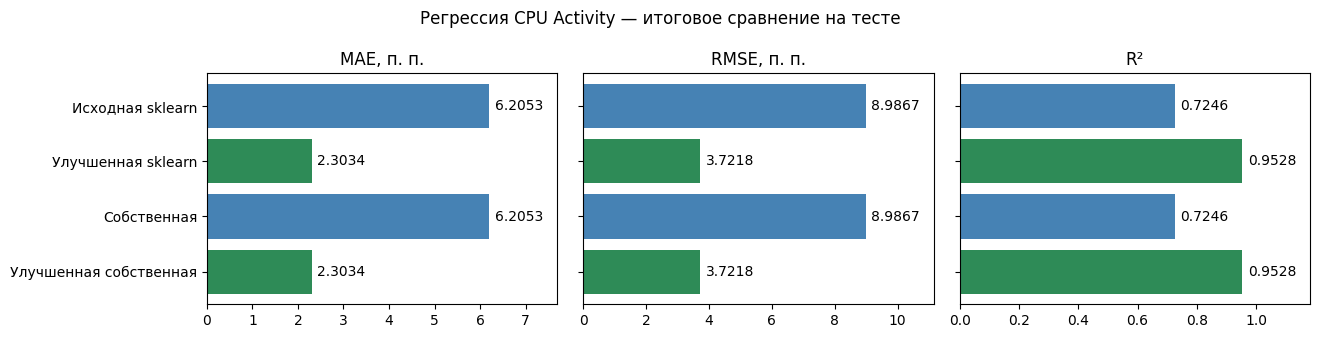

In [11]:
colors = ["steelblue", "seagreen", "steelblue", "seagreen"]
for title, table in [
    ("Классификация манёвров", classification_final),
    ("Регрессия CPU Activity", regression_final),
]:
    fig, axes = plt.subplots(
        1, len(table.columns), figsize=(4.1 * len(table.columns) + 1, 3.4), sharey=True,
    )
    for ax, metric in zip(axes, table.columns):
        bars = ax.barh(table.index, table[metric], color=colors)
        ax.bar_label(bars, fmt="%.4f", padding=4)
        ax.set_title(metric)
        ax.margins(x=0.24)
    axes[0].invert_yaxis()
    fig.suptitle(title + " — итоговое сравнение на тесте")
    fig.tight_layout()
    plt.show()

### Общий вывод

- **Логистическая регрессия.** Настройки из раздела 3 улучшили F1-macro на кросс-валидации с 0,5709 до 0,5872. На тесте качество снизилось у обеих реализаций. Для собственной модели Accuracy составила 0,7134 → 0,6694, F1-macro — 0,6928 → 0,6652. Оптимизатор сошёлся за 274 и 293 итераций. В сравнении со sklearn различаются 0 исходных и 0 улучшенных меток из 1092. Возможные причины расхождений — порядок операций с плавающей точкой и чувствительность выбора класса при близких оценках.
- **Линейная регрессия.** Полиномиальные признаки степени 2 и ограничение прогнозов улучшили все метрики на тесте. Для собственной модели MAE составила 6,2053 → 2,3034 п. п., RMSE — 8,9867 → 3,7218 п. п., R² — 0,7246 → 0,9528. Максимальные различия со sklearn составили 0 и 0,000305 п. п. для исходного и улучшенного вариантов соответственно. Небольшие различия возможны из-за численных особенностей решателей МНК и масштабов полиномиальных признаков.